In [31]:
%pip install matplotlib


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
# from google.colab.patches import cv2_imshow
from PIL import Image 
from sklearn.model_selection import train_test_split

In [6]:
with_mask_files = os.listdir('with_mask')
print(with_mask_files[0:5])
print(with_mask_files[-5:])

['with_mask_1.jpg', 'with_mask_10.jpg', 'with_mask_100.jpg', 'with_mask_1000.jpg', 'with_mask_1001.jpg']
['with_mask_995.jpg', 'with_mask_996.jpg', 'with_mask_997.jpg', 'with_mask_998.jpg', 'with_mask_999.jpg']


In [7]:
without_mask_files = os.listdir('without_mask')
print(without_mask_files[0:5])


['without_mask_1.jpg', 'without_mask_10.jpg', 'without_mask_100.jpg', 'without_mask_1000.jpg', 'without_mask_1001.jpg']


In [8]:
len(with_mask_files), len(without_mask_files)

(3725, 3828)

In [9]:
with_mask_labels = [1] * len(with_mask_files)
without_mask_labels = [0] * len(without_mask_files)

In [10]:
with_mask_labels[0:10]

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [11]:
labels = with_mask_labels + without_mask_labels 
len(labels)

7553

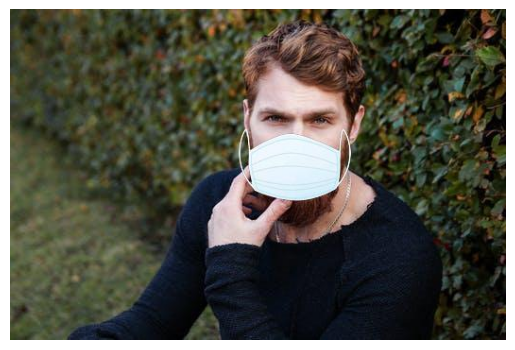

In [12]:
img = Image.open("with_mask\\with_mask_1.jpg")
plt.imshow(img)
plt.axis('off')
plt.show()

In [13]:
with_mask_path = 'with_mask/'

data = []

for img_files in with_mask_files:
    image = Image.open(with_mask_path + img_files)
    image = image.resize((128,128))
    image = image.convert('RGB')
    image = np.array(image)
    data.append(image)

without_mask_path = 'without_mask/'

for img_files in without_mask_files:
    image = Image.open(without_mask_path + img_files)
    image = image.resize((128,128))
    image = image.convert('RGB')
    image = np.array(image)
    data.append(image)


c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [14]:
type(data)

list

In [15]:
len(data)

7553

In [16]:
data[0]

array([[[50, 58, 31],
        [46, 55, 33],
        [56, 58, 42],
        ...,
        [27, 32, 25],
        [29, 33, 19],
        [33, 40, 17]],

       [[47, 54, 30],
        [49, 58, 36],
        [59, 63, 40],
        ...,
        [18, 21, 11],
        [37, 42, 31],
        [31, 41, 23]],

       [[51, 58, 37],
        [50, 59, 37],
        [59, 64, 37],
        ...,
        [45, 44, 30],
        [29, 34, 27],
        [20, 30, 18]],

       ...,

       [[63, 73, 37],
        [66, 75, 41],
        [74, 84, 50],
        ...,
        [ 5,  3,  0],
        [20, 19, 14],
        [17, 16, 12]],

       [[58, 72, 34],
        [60, 70, 39],
        [68, 75, 49],
        ...,
        [16, 15, 12],
        [15, 13, 10],
        [13,  9,  7]],

       [[53, 69, 30],
        [53, 64, 37],
        [57, 64, 42],
        ...,
        [18, 18, 16],
        [16, 13, 12],
        [19, 12, 13]]], shape=(128, 128, 3), dtype=uint8)

In [17]:
X = np.array(data)
Y = np.array(labels)

In [18]:
print(X.shape)
print(Y.shape)

(7553, 128, 128, 3)
(7553,)


In [19]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

In [20]:
# scaling the data

X_train_scaled = X_train.astype('float')/255.0

X_test_scaled = X_test.astype('float')/255.0

In [ ]:
%pip install tensorflow


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [21]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [22]:
cnn = Sequential([
    Conv2D(filters=32, kernel_size=(3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(filters=64, kernel_size=(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(units=128, activation='relu'),
    Dropout(0.5),
    Dense(units=64, activation='relu'),
    Dropout(0.5),
    Dense(units=2, activation='softmax')
])

c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [24]:
history = cnn.fit(X_train_scaled, Y_train, validation_data=(X_test_scaled, Y_test), epochs=10, batch_size=32,verbose=1)

Epoch 1/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 211s 963ms/step - accuracy: 0.7799 - loss: 0.4930 - val_accuracy: 0.8901 - val_loss: 0.2749
Epoch 2/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 110s 560ms/step - accuracy: 0.8846 - loss: 0.2912 - val_accuracy: 0.8954 - val_loss: 0.2348
Epoch 3/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 72s 382ms/step - accuracy: 0.9111 - loss: 0.2364 - val_accuracy: 0.9093 - val_loss: 0.2164
Epoch 4/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 77s 408ms/step - accuracy: 0.9245 - loss: 0.1988 - val_accuracy: 0.9292 - val_loss: 0.2015
Epoch 5/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 72s 377ms/step - accuracy: 0.9358 - loss: 0.1610 - val_accuracy: 0.9292 - val_loss: 0.1662
Epoch 6/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 78s 410ms/step - accuracy: 0.9543 - loss: 0.1278 - val_accuracy: 0.9325 - val_loss: 0.1728
Epoch 7/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 74s 394ms/step - accuracy: 0.9532 - loss: 0.1282 - val_accuracy: 0.9345 - val_loss: 0.1786
Epoch 8/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 74s 392ms/step - accuracy: 0.9681 - loss:

In [25]:
loss, accuracy = cnn.evaluate(X_test_scaled, Y_test)
print('Test Accuracy =', accuracy)

48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 112ms/step - accuracy: 0.9523 - loss: 0.1627
Test Accuracy = 0.9523494243621826


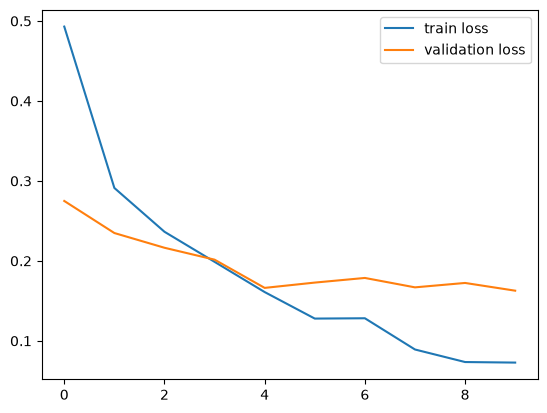

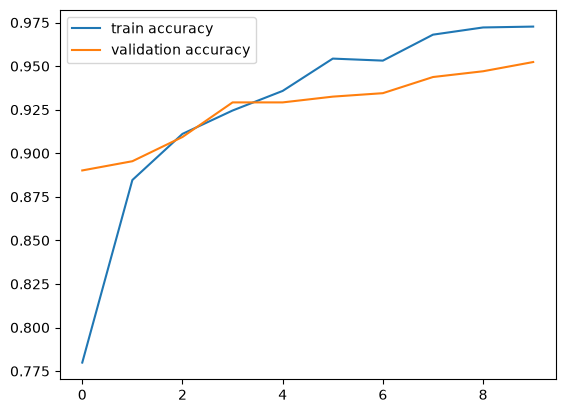

In [26]:
h = history

# plot the loss value
plt.plot(h.history['loss'], label='train loss')
plt.plot(h.history['val_loss'], label='validation loss')
plt.legend()
plt.show()

# plot the accuracy value
plt.plot(h.history['accuracy'], label='train accuracy')
plt.plot(h.history['val_accuracy'], label='validation accuracy')
plt.legend()
plt.show()

In [27]:
import matplotlib.pyplot as plt
import cv2


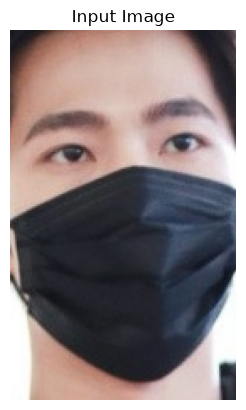

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 658ms/step
Prediction Probabilities: [[0.48249707 0.51750296]]
Predicted Label: 1
✅ The person in the image is wearing a mask.


In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Get image path
input_image_path = input("Path of the image to be predicted: ")

# Read image
input_image = cv2.imread(input_image_path)

# Check if image was loaded successfully
if input_image is None:
    print("Error: Could not load the image. Please check the file path.")
else:
    # Display image using matplotlib
    input_image_rgb = cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB)
    plt.imshow(input_image_rgb)
    plt.title("Input Image")
    plt.axis("off")
    plt.show()

    # Resize image
    input_image_resized = cv2.resize(input_image, (128, 128))

    # Normalize
    input_image_scaled = input_image_resized / 255.0

    # Add batch dimension
    input_image_reshaped = np.reshape(input_image_scaled, (1, 128, 128, 3))

    # Predict
    input_prediction = cnn.predict(input_image_reshaped)

    print("Prediction Probabilities:", input_prediction)

    # Get predicted class
    input_pred_label = np.argmax(input_prediction)

    print("Predicted Label:", input_pred_label)

    # Display result
    if input_pred_label == 1:
        print("✅ The person in the image is wearing a mask.")
    else:
        print("❌ The person in the image is not wearing a mask.")

In [29]:
cnn.save("face_mask_detector.keras")